<a href="https://colab.research.google.com/github/Mangbunn/nets7052_fa26/blob/main/Broadus_Comp_Meths_HW3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Q2

In [ ]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rc
from joblib import Parallel, delayed
import time
import random
import os

rc('axes', axisbelow=True)
rc('axes', fc='w')
rc('figure', fc='w')
rc('savefig', fc='w')

In [ ]:
def random_walk_network(G, start_node, stop_node, steps):
    """
    Simulates a random walk on a network, represented as a graph.

    Starting from the specified node, the walker moves to a randomly selected
    neighboring node at each step. If the walker reaches an isolated node (one with
    no neighbors), the walk terminates early. Otherwize, the walker stops at the specified stop node.

    Parameters
    ----------
    G : networkx.Graph
        The graph representing the network on which the random walk is performed.
        Nodes should be connected by edges, as each edge represents a possible transition.
    start_node : node
        The node in G where the random walk starts. Must be a valid node in the graph.
    stop_node : node
        The node in G where the random walk stops. Must be a valid node in the graph. Must be in the same component as the start node.
    steps : int
        The number of steps the random walker will attempt to take. Note that the walk
        may terminate early if an isolated node is reached.

    Returns
    -------
    path : list
        A list of nodes representing the path taken by the walker, starting from
        `start_node`. The list length will be `steps + 1` unless the walk terminates early
        at an isolated node.

    Notes
    -----
    - At each step, the walker chooses a neighboring node uniformly at random.
    - If the walker reaches an isolated node (one with no neighbors), the walk stops early.
    - This function assumes the graph `G` is undirected, but it can be adapted for
      directed networks by modifying the neighbor selection.

    Examples
    --------
    >>> G = nx.path_graph(5)  # Simple path graph with 5 nodes
    >>> random_walk_network(G, start_node=0, steps=10)
    [0, 1, 2, 1, 2, 3, 2, 1, 0, 1, 2]
    """
    # Initialize the path list with the starting node
    path = [start_node]

    # Set the current node to the starting node
    current_node = start_node

    # Iterate for the specified number of steps
    for _ in range(steps):
        # Get the list of neighbors of the current node
        neighbors = list(G.neighbors(current_node))

        # If the current node has neighbors, move to a randomly chosen neighbor
        if neighbors:
            next_node = np.random.choice(neighbors)  # Select a random neighbor
            path.append(next_node)  # Append the selected neighbor to the path
            current_node = next_node  # Update the current node
            if current_node == stop_node:
                break
        else:
            # If no neighbors (isolated node), terminate the walk early
            break


    return len(path)  # Return the full path taken by the walker

In [ ]:
G = nx.karate_club_graph()
print(random_walk_network(G, start_node=0, stop_node=33, steps=1000))
print(random_walk_network(G, start_node=0, stop_node=13, steps=1000))
print(random_walk_network(G, start_node=0, stop_node=6, steps=1000))

#Sorry for stealing you code lol

6
57
8


In [ ]:
def compute_mean_commute_time_analytical(G):
    """
    Computes the mean commute time across all pairs of nodes in a connected graph G
    using the pseudo-inverse of the Laplacian matrix. Who doesnt love spectrial graph theory :D
    """

    n = G.number_of_nodes()
    if n <= 1:
        return 0

    # Number of edges and volume
    m = G.number_of_edges()
    vol = 2 * m

    # Laplacian matrix L
    L = nx.laplacian_matrix(G).toarray()

    # Moore-Penrose pseudo-inverse of the Laplacian
    L_pinv = np.linalg.pinv(L)

    # Compute commute time for all pairs
    # C_ij = vol * (L_pinv_ii + L_pinv_jj - 2 * L_pinv_ij)
    diag = np.diagonal(L_pinv)

    # Using matrix operations for efficiency
    # L_pinv_ii + L_pinv_jj - 2 * L_pinv_ij
    C = vol * (diag[:, None] + diag[None, :] - 2 * L_pinv)

    # Average over all unique pairs of distinct nodes
    # Total number of unique pairs is n * (n - 1) / 2
    triu_indices = np.triu_indices(n, k=1)
    mean_commute_time = np.mean(C[triu_indices])

    return mean_commute_time

In [ ]:
# Initialize lists to store mean commute times for 10 realizations
er_commute_times = []
ba_commute_times = []

num_samples = 10
N = 500

print("Starting simulation...")
for i in range(num_samples):
    # 1. Generate ER network
    # avg(k) = 8 -> p = 8 / (N - 1) = 8 / 499
    G_ER = nx.erdos_renyi_graph(N, 8 / 499)
    # Get LCC
    lcc_er_nodes = max(nx.connected_components(G_ER), key=len)
    LCC_ER = G_ER.subgraph(lcc_er_nodes).copy()

    # 2. Generate Barabási-Albert network with m = 4
    G_BA = nx.barabasi_albert_graph(N, 4)
    # Get LCC
    lcc_ba_nodes = max(nx.connected_components(G_BA), key=len)
    LCC_BA = G_BA.subgraph(lcc_ba_nodes).copy()

    # Compute mean commute times
    er_mean = compute_mean_commute_time_analytical(LCC_ER)
    ba_mean = compute_mean_commute_time_analytical(LCC_BA)

    er_commute_times.append(er_mean)
    ba_commute_times.append(ba_mean)

    print(f"Sample {i+1}/{num_samples} completed: ER LCC Nodes = {LCC_ER.number_of_nodes()}, BA LCC Nodes = {LCC_BA.number_of_nodes()}")

# Calculate final averages across 10 samples
avg_er_commute = np.mean(er_commute_times)
avg_ba_commute = np.mean(ba_commute_times)

print("\n--- Results ---")
print(f"Average Commute Time in Erdos-Renyi (10 samples): {avg_er_commute:.2f}")
print(f"Average Commute Time in Barabasi-Albert (10 samples): {avg_ba_commute:.2f}")

Starting simulation...
Sample 1/10 completed: ER LCC Nodes = 500, BA LCC Nodes = 500
Sample 2/10 completed: ER LCC Nodes = 500, BA LCC Nodes = 500
Sample 3/10 completed: ER LCC Nodes = 500, BA LCC Nodes = 500
Sample 4/10 completed: ER LCC Nodes = 500, BA LCC Nodes = 500
Sample 5/10 completed: ER LCC Nodes = 500, BA LCC Nodes = 500
Sample 6/10 completed: ER LCC Nodes = 500, BA LCC Nodes = 500
Sample 7/10 completed: ER LCC Nodes = 500, BA LCC Nodes = 500
Sample 8/10 completed: ER LCC Nodes = 500, BA LCC Nodes = 500
Sample 9/10 completed: ER LCC Nodes = 500, BA LCC Nodes = 500
Sample 10/10 completed: ER LCC Nodes = 500, BA LCC Nodes = 500

--- Results ---
Average Commute Time in Erdos-Renyi (10 samples): 1349.29
Average Commute Time in Barabasi-Albert (10 samples): 1582.11


im stealing more of your code sorrt not sorry

In [ ]:
import random
def random_walk_coverage_time(G, start_node=None):
    """
    Simulates a random walk on a network to determine the time taken to cover all nodes.

    Starting from a specified or random node, the walker moves to a randomly chosen
    neighboring node at each step. The walk continues until all nodes in the graph
    have been visited at least once.

    Parameters
    ----------
    G : networkx.Graph
        The graph representing the network on which the random walk is performed.
    start_node : node, optional
        The node where the random walk starts. If None, a random node is chosen.

    Returns
    -------
    coverage_time : int
        The number of steps required to visit every node in the graph at least once.
    path : list
        A list of nodes representing the path taken by the walker.

    Notes
    -----
    - This function assumes the graph `G` is undirected and connected.
    - If the graph has isolated components, some nodes may remain unvisited.

    Examples
    --------
    >>> G = nx.path_graph(5)
    >>> random_walk_coverage_time(G)
    (7, [2, 1, 0, 1, 2, 3, 4])
    """

    # Initialize the starting node
    source = start_node if start_node is not None else random.choice(list(G.nodes))
    nodes_covered = set([source])  # Track visited nodes
    path = [source]                # Track the path of the walker
    N = G.number_of_nodes()        # Total number of nodes in the graph
    t = 0                          # Step counter

    if not nx.is_connected(G):
        return 'help',[]
#         print('Help')

    # Continue walking until all nodes have been visited
    while len(nodes_covered) < N:
        # Get the neighbors of the current node
        neighbors = list(G.neighbors(source))

        # Choose a random neighbor and move there
        target = random.choice(neighbors)
        path.append(target)
        nodes_covered.add(target)  # Add the new node to the visited set
        source = target            # Update the current node
        t += 1                     # Increment the step count

    return t, path  # Return the time to cover all nodes and the path taken


# Ns = np.logspace(1, 3, 20)
Ns = [10, 50, 100, 500, 1000, 10000]
m = 6
n_iter = 100

cover_ba = []
cover_er = []

for N in Ns:
    N = int(N)
    print(N)
    cover_ba_n = []
    cover_er_n = []
    for _ in range(n_iter):
        G_ba = nx.barabasi_albert_graph(N, m)
        cover_t_ba, _ = random_walk_coverage_time(G_ba)
        cover_ba_n.append(cover_t_ba)

        G_er = nx.erdos_renyi_graph(N, nx.density(G_ba))
        cover_t_er, _ = random_walk_coverage_time(G_er)
        if not cover_t_er == 'help':
            cover_er_n.append(cover_t_er)

    cover_ba.append(np.mean(cover_ba_n))
    cover_er.append(np.mean(cover_er_n))

10
50
100
500
1000


In [ ]:
fig, ax = plt.subplots(1,1,figsize=(4,3),dpi=150)

ax.loglog(Ns, cover_er, 'o-', label='ER')
ax.loglog(Ns, cover_ba, 'o-', label='BA')
ax.loglog(Ns, [N*np.log(N) for N in Ns], label=r'$N \log N$')

ax.legend()
ax.set_xlabel('Network size, N')
ax.set_ylabel('Cover time')

plt.show()


Q3

In [ ]:
import networkx as nx
import random

def epidemic_model_network(G, compartments, seed_num, T, transmissions, params):
    """
    Simulate an epidemic model on a networkx graph.

    Parameters:
    -----------
    G : networkx.Graph
        The input graph representing the contact network.
    compartments : dict
        Dictionary where keys are compartment names (e.g., "S", "I", "R") and
        values are lists to store the number of nodes in each compartment at each timestep.
    seed_num : int
        Number of initial infectious nodes.
    T : int
        Number of timesteps to simulate.
    transmissions : dict
        Dictionary where keys are current statuses (e.g., "S") and values are tuples
        `(new_status, trans_type, trans_rate_key)`. `trans_type` is either "contagion"
        or "spontaneous".
    params : dict
        Dictionary mapping parameter names (e.g., "beta", "gamma") to their numerical values.

    Returns:
    --------
    compartments : dict
        Updated dictionary where each key contains a list of counts over time for each compartment.
    """
    # Initialize node states
    all_nodes = list(G.nodes())
    node_status = {node: {"status": None,
                          "next_status": None}
                   for node in all_nodes}

    # Initialize compartments
    for cmpt in compartments.keys():
        compartments[cmpt].append(0)

    # Set all nodes to susceptible initially
    for node in all_nodes:
        node_status[node]["status"] = "S"
        compartments["S"][0] += 1

    # Seed infectious nodes
    seed_nodes = random.sample(all_nodes, seed_num)
    for node in seed_nodes:
        node_status[node]["status"] = "I"
        compartments["S"][0] -= 1
        compartments["I"][0] += 1

    # Simulation loop over timesteps
    for t in range(1, T):
        # Process each node's status
        for node in all_nodes:
            current_status = node_status[node]["status"]
            neighbors = list(G.neighbors(node))

            # Check if the current status has a transition rule
            if current_status in transmissions:
                new_status, trans_type, trans_rate_key = transmissions[current_status]
                trans_rate = params[trans_rate_key]

                # Contagion-based transition
                if trans_type == "contagion":
                    for neighbor in neighbors:
                        if node_status[neighbor]["status"] == new_status:
                            if random.uniform(0, 1) < trans_rate:
                                node_status[node]["next_status"] = new_status
                                break

                # Spontaneous transition
                elif trans_type == "spontaneous":
                    if random.uniform(0, 1) < trans_rate:
                        node_status[node]["next_status"] = new_status

        # Update compartments for the current timestep
        for cmpt in compartments.keys():
            compartments[cmpt].append(0)

        # Update node statuses and compartments
        for node in all_nodes:
            if node_status[node]["next_status"]:
                # Update the node's status
                node_status[node]["status"] = node_status[node]["next_status"]
                node_status[node]["next_status"] = None

            # Count the node in its current compartment
            compartments[node_status[node]["status"]][t] += 1


    return compartments

In [ ]:
nodes_file = "polblogs_nodes_class.tsv"
edges_file = "polblogs_edges_class.tsv"

nodes_df = pd.read_csv(nodes_file, sep='\t', header=None)
edges_df = pd.read_csv(edges_file, sep='\t', header=None)

G_raw = nx.Graph()   # nx.Graph merges repeated edges and ignores direction
for _, row in nodes_df.iterrows():
    G_raw.add_node(row[0])
for _, row in edges_df.iterrows():
    G_raw.add_edge(row[0], row[1])

G_raw.remove_edges_from(nx.selfloop_edges(G_raw))
lcc_nodes = max(nx.connected_components(G_raw), key=len)
G_pol = G_raw.subgraph(lcc_nodes).copy()

print(f"Nodes in LCC: {G_pol.number_of_nodes()} (expected 1,222)")
print(f"Edges in LCC: {G_pol.number_of_edges()} (expected 16,714)")

Nodes in LCC: 1222 (expected 1,222)
Edges in LCC: 16714 (expected 16,714)


In [ ]:
degrees = np.array([d for _, d in G_pol.degree()])
k_avg = degrees.mean()
k2_avg = (degrees ** 2).mean()

A = nx.to_numpy_array(G_pol)
lambda_1 = np.linalg.eigvalsh(A)[-1]

threshold_hom = 1 / k_avg
threshold_MF  = k_avg / k2_avg
threshold_eig = 1 / lambda_1

print(f"<k>        = {k_avg:.4f}")
print(f"<k^2>      = {k2_avg:.4f}")
print(f"lambda_1   = {lambda_1:.4f}")
print(f"1/<k>        = {threshold_hom:.5f}")
print(f"<k>/<k^2>    = {threshold_MF:.5f}")
print(f"1/lambda_1   = {threshold_eig:.5f}")

<k>        = 27.3552
<k^2>      = 2222.9771
lambda_1   = 74.0820
1/<k>        = 0.03656
<k>/<k^2>    = 0.01231
1/lambda_1   = 0.01350


We will run the simulations for values of $\beta/\mu$ ranging logarithmically from 0.005 to 0.1, using $\mu = 0.1$ and averaging over 10 independent runs for each point.

In [ ]:
def simulate_sis_network(G, beta, mu, T=1500, average_last_steps=500, seed=None):
    """Run one SIS simulation and return prevalence rho averaged over the last steps."""
    if seed is not None:
        random.seed(seed)
    n = G.number_of_nodes()

    compartments = {"S": [], "I": []}
    transmissions = {"S": ("I", "contagion", "beta"),      # infection, per infected neighbor
                     "I": ("S", "spontaneous", "mu")}      # recovery
    params = {"beta": beta, "mu": mu}

    comp = epidemic_model_network(G, compartments, n // 2, T, transmissions, params)

    I = comp["I"] + [0] * (T - len(comp["I"]))   # no-op unless you add early stopping
    return np.mean(I[-average_last_steps:]) / n

In [ ]:
import time

t0 = time.time()
rho_test = simulate_sis_network(G_pol, 0.05 * 0.1, 0.1, seed=0)
print(f"rho = {rho_test:.4f}, took {time.time() - t0:.1f} s")

rho = 0.3090, took 10.4 s


In [ ]:
mu = 0.1
beta_over_mu_vals = np.logspace(np.log10(0.005), np.log10(0.1), 25)
num_runs = 10

results = Parallel(n_jobs=-1, verbose=5)(
    delayed(simulate_sis_network)(G_pol, ratio * mu, mu, seed=i * num_runs + k)
    for i, ratio in enumerate(beta_over_mu_vals)
    for k in range(num_runs)
)
runs = np.array(results).reshape(len(beta_over_mu_vals), num_runs)
prevalence_results = runs.mean(axis=1)

for ratio, rho in zip(beta_over_mu_vals, prevalence_results):
    print(f"beta/mu = {ratio:.4f} -> rho = {rho:.4f}")

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  14 tasks      | elapsed:  2.4min
[Parallel(n_jobs=-1)]: Done  68 tasks      | elapsed: 11.9min
[Parallel(n_jobs=-1)]: Done 158 tasks      | elapsed: 28.5min


beta/mu = 0.0050 -> rho = 0.0000
beta/mu = 0.0057 -> rho = 0.0000
beta/mu = 0.0064 -> rho = 0.0000
beta/mu = 0.0073 -> rho = 0.0000
beta/mu = 0.0082 -> rho = 0.0000
beta/mu = 0.0093 -> rho = 0.0000
beta/mu = 0.0106 -> rho = 0.0000
beta/mu = 0.0120 -> rho = 0.0000
beta/mu = 0.0136 -> rho = 0.0000
beta/mu = 0.0154 -> rho = 0.0042
beta/mu = 0.0174 -> rho = 0.0554
beta/mu = 0.0197 -> rho = 0.0861
beta/mu = 0.0224 -> rho = 0.1204
beta/mu = 0.0253 -> rho = 0.1490
beta/mu = 0.0287 -> rho = 0.1803
beta/mu = 0.0325 -> rho = 0.2108
beta/mu = 0.0368 -> rho = 0.2411
beta/mu = 0.0417 -> rho = 0.2690
beta/mu = 0.0473 -> rho = 0.2991
beta/mu = 0.0536 -> rho = 0.3253
beta/mu = 0.0607 -> rho = 0.3525
beta/mu = 0.0688 -> rho = 0.3801
beta/mu = 0.0779 -> rho = 0.4053
beta/mu = 0.0883 -> rho = 0.4317
beta/mu = 0.1000 -> rho = 0.4564


[Parallel(n_jobs=-1)]: Done 250 out of 250 | elapsed: 42.0min finished


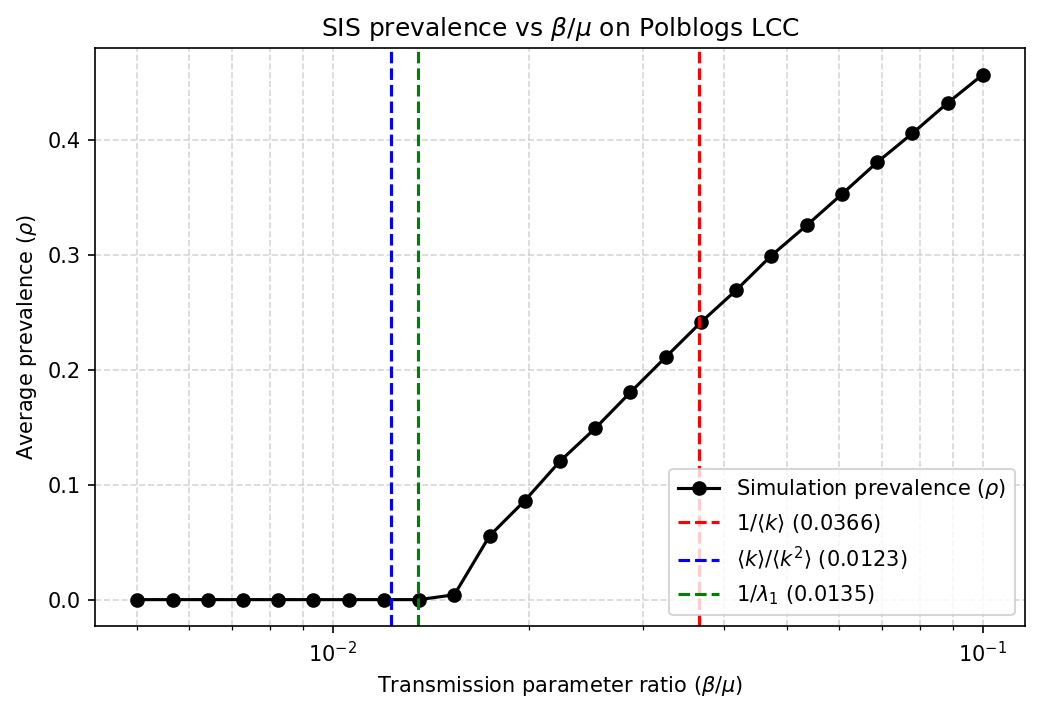

In [ ]:
plt.figure(figsize=(8, 5), dpi=150)
plt.plot(beta_over_mu_vals, prevalence_results, 'o-', color='black',
         label=r'Simulation prevalence ($\rho$)')

plt.axvline(x=threshold_hom, color='red', linestyle='--',
            label=rf'$1/\langle k\rangle$ ({threshold_hom:.4f})')
plt.axvline(x=threshold_MF, color='blue', linestyle='--',
            label=rf'$\langle k\rangle/\langle k^2\rangle$ ({threshold_MF:.4f})')
plt.axvline(x=threshold_eig, color='green', linestyle='--',
            label=rf'$1/\lambda_1$ ({threshold_eig:.4f})')

plt.xscale('log')
plt.xlabel(r'Transmission parameter ratio ($\beta/\mu$)')
plt.ylabel(r'Average prevalence ($\rho$)')
plt.title(r'SIS prevalence vs $\beta/\mu$ on Polblogs LCC')
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.show()

In [ ]:
N = G_pol.number_of_nodes()                     # 1222
nodes = list(G_pol.nodes())
nbrs = {v: list(G_pol.neighbors(v)) for v in nodes}
deg = dict(G_pol.degree())                      # degrees in the ORIGINAL network

mu = 0.1
beta = 0.05 * mu                                # beta/mu = 0.05
g_vals = np.round(np.arange(0, 0.80001, 0.05), 3)
k_vals = [int(round(g * N)) for g in g_vals]    # number of immunized nodes at each g
k_max = max(k_vals)
num_runs = 10
strategies = ["random", "targeted", "acquaintance"]

def order_random(rng):
    o = nodes[:]
    rng.shuffle(o)
    return o

def order_targeted(rng):
    # highest original degree first; ties broken randomly
    return sorted(nodes, key=lambda v: (-deg[v], rng.random()))

def order_acquaintance(rng, k_max):
    # pick a random node, immunize a random neighbor, repeat until k_max DIFFERENT nodes
    chosen, seen = [], set()
    while len(chosen) < k_max:
        v = rng.choice(nodes)
        u = rng.choice(nbrs[v])
        if u not in seen:
            seen.add(u)
            chosen.append(u)
    return chosen

orders = {s: [] for s in strategies}
for r in range(num_runs):
    rng = random.Random(10_000 + r)
    orders["random"].append(order_random(rng))
    orders["targeted"].append(order_targeted(rng))
    orders["acquaintance"].append(order_acquaintance(rng, k_max))

In [ ]:
def sis_after_immunization(G, immunized, beta, mu, N, T=1500, average_last_steps=500, seed=None):
    """Delete immunized nodes, run SIS on what's left, return (rho, died_out, 1/lambda_1)."""
    if seed is not None:
        random.seed(seed)
    H = G.subgraph([v for v in G.nodes() if v not in immunized]).copy()
    n_rem = H.number_of_nodes()

    compartments = {"S": [], "I": []}
    transmissions = {"S": ("I", "contagion", "beta"),
                     "I": ("S", "spontaneous", "mu")}
    params = {"beta": beta, "mu": mu}

    # half of the NON-immunized nodes start infected
    comp = epidemic_model_network(H, compartments, n_rem // 2, T, transmissions, params)

    I = comp["I"] + [0] * (T - len(comp["I"]))      # no-op unless early stopping is added
    rho = np.mean(I[-average_last_steps:]) / N      # fraction of ALL N original nodes
    died_out = (I[-1] == 0)

    if H.number_of_edges() == 0:
        inv_lam = np.inf                            # no edges left
    else:
        inv_lam = 1 / np.linalg.eigvalsh(nx.to_numpy_array(H))[-1]
    return rho, died_out, inv_lam

In [ ]:
jobs = [(s, gi, r) for s in strategies for gi in range(len(g_vals)) for r in range(num_runs)]

t0 = time.time()
out = Parallel(n_jobs=-1, verbose=5)(
    delayed(sis_after_immunization)(
        G_pol, set(orders[s][r][:k_vals[gi]]), beta, mu, N, seed=idx)
    for idx, (s, gi, r) in enumerate(jobs)
)
print(f"done in {(time.time() - t0)/60:.1f} min")

rho_arr  = np.zeros((3, len(g_vals), num_runs))
died_arr = np.zeros((3, len(g_vals), num_runs), dtype=bool)
inv_arr  = np.zeros((3, len(g_vals), num_runs))
for (s, gi, r), (rho, died, inv) in zip(jobs, out):
    si = strategies.index(s)
    rho_arr[si, gi, r], died_arr[si, gi, r], inv_arr[si, gi, r] = rho, died, inv

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  14 tasks      | elapsed:  2.2min
[Parallel(n_jobs=-1)]: Done  68 tasks      | elapsed:  8.5min
[Parallel(n_jobs=-1)]: Done 158 tasks      | elapsed: 12.8min
[Parallel(n_jobs=-1)]: Done 284 tasks      | elapsed: 18.6min
[Parallel(n_jobs=-1)]: Done 446 tasks      | elapsed: 26.1min


done in 26.7 min


[Parallel(n_jobs=-1)]: Done 510 out of 510 | elapsed: 26.7min finished


In [ ]:
mean_rho = rho_arr.mean(axis=2)             # shape (3, n_g)
med_inv  = np.median(inv_arr, axis=2)       # median 1/lambda_1 over the 10 runs
target   = beta / mu                        # 0.05

g_stop, g_cross = {}, {}
for si, s in enumerate(strategies):
    all_died = died_arr[si].all(axis=1)
    g_stop[s] = g_vals[np.argmax(all_died)] if all_died.any() else None
    crossed = med_inv[si] >= target
    g_cross[s] = g_vals[np.argmax(crossed)] if crossed.any() else None

print(f"{'strategy':<14}{'(i) first g, all 10 died out':<32}{'(iv) first g, median 1/lambda_1 >= 0.05'}")
for s in strategies:
    a = g_stop[s] if g_stop[s] is not None else "not reached in tested range"
    b = g_cross[s] if g_cross[s] is not None else "no crossing in tested range"
    print(f"{s:<14}{str(a):<32}{b}")

table = pd.DataFrame({"g": g_vals})
for si, s in enumerate(strategies):
    table[f"{s} rho"] = mean_rho[si].round(4)
    table[f"{s} #died"] = died_arr[si].sum(axis=1)
    table[f"{s} med 1/lam1"] = med_inv[si].round(4)
print(table.to_string(index=False))

strategy      (i) first g, all 10 died out    (iv) first g, median 1/lambda_1 >= 0.05
random        0.7                             0.8
targeted      0.1                             0.15
acquaintance  0.25                            0.3
   g  random rho  random #died  random med 1/lam1  targeted rho  targeted #died  targeted med 1/lam1  acquaintance rho  acquaintance #died  acquaintance med 1/lam1
0.00      0.3100             0             0.0135        0.3114               0               0.0135            0.3114                   0                   0.0135
0.05      0.2832             0             0.0142        0.1408               0               0.0268            0.2241                   0                   0.0167
0.10      0.2548             0             0.0153        0.0000              10               0.0463            0.1560                   0                   0.0209
0.15      0.2289             0             0.0161        0.0000              10               0.0701       

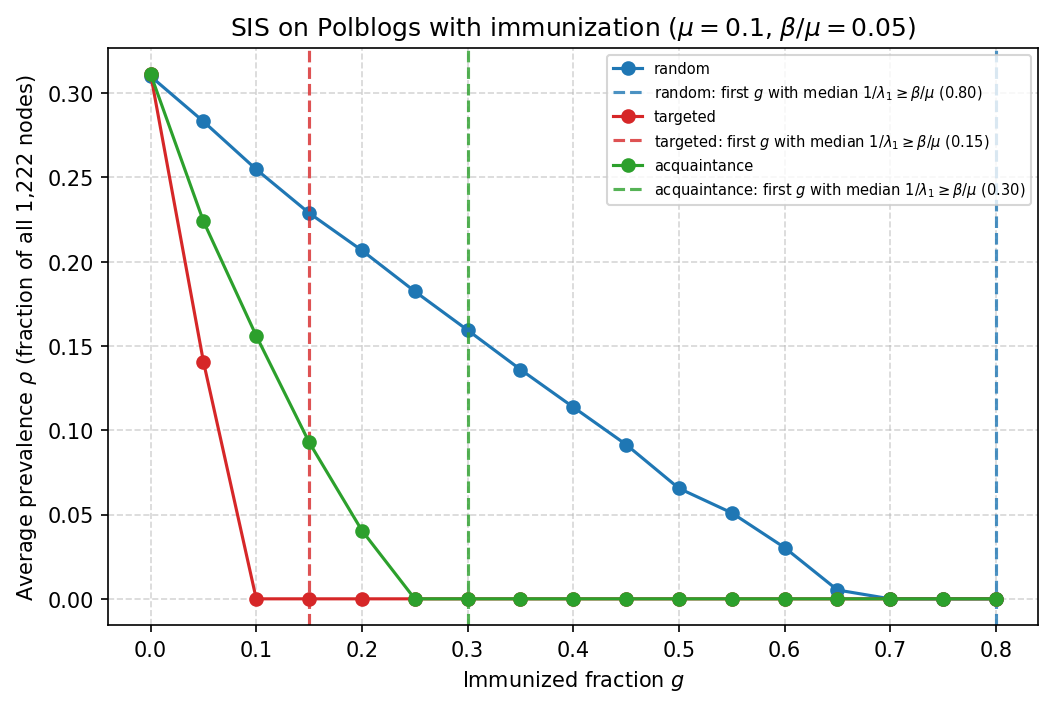

In [ ]:
colors = {"random": "tab:blue", "targeted": "tab:red", "acquaintance": "tab:green"}
plt.figure(figsize=(8, 5), dpi=150)
for si, s in enumerate(strategies):
    plt.plot(g_vals, mean_rho[si], 'o-', color=colors[s], label=f"{s}")
    if g_cross[s] is not None:
        plt.axvline(g_cross[s], color=colors[s], linestyle='--', alpha=0.8,
                    label=rf"{s}: first $g$ with median $1/\lambda_1 \geq \beta/\mu$ ({g_cross[s]:.2f})")
plt.xlabel(r'Immunized fraction $g$')
plt.ylabel(r'Average prevalence $\rho$ (fraction of all 1,222 nodes)')
plt.title(r'SIS on Polblogs with immunization ($\mu=0.1$, $\beta/\mu=0.05$)')
plt.legend(fontsize=7)
plt.grid(True, ls='--', alpha=0.5)
plt.show()